In [19]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplot, subplots
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (MinMaxScaler, OneHotEncoder,
                                   OrdinalEncoder, StandardScaler)
from scipy.spatial.distance import cityblock, cosine, euclidean
import matplotlib.pyplot as plt

##### 1. Premier regard.

In [3]:
df = pd.read_csv("atelier_connecte.csv")
df.shape #afficher les dimensions du dataframe
df.info() #Dtypes, Non-null Count
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horodatage            720 non-null    str    
 1   machine_id            720 non-null    str    
 2   temperature           696 non-null    float64
 3   vibration             688 non-null    float64
 4   courant               690 non-null    float64
 5   cadence               702 non-null    float64
 6   vibration_pic         720 non-null    float64
 7   vib_f1                720 non-null    float64
 8   vib_f2                720 non-null    float64
 9   vib_f3                720 non-null    float64
 10  vib_f4                720 non-null    float64
 11  defaut                720 non-null    int64  
 12  alarme_temperature    720 non-null    int64  
 13  alarme_vibration      720 non-null    int64  
 14  alarme_courant        720 non-null    int64  
 15  alarme_cadence        720 non-null

,temperature,vibration,courant,cadence,vibration_pic,vib_f1,vib_f2,vib_f3,vib_f4,defaut,alarme_temperature,alarme_vibration,alarme_courant,alarme_cadence
count,696.000000,688.000000,690.000000,702.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000,720.000000
mean,76.375235,2.860442,14.525110,48.817425,4.702682,1.189195,0.876973,0.514633,0.257172,0.109722,0.136111,0.155556,0.075000,0.077778
std,13.723192,1.333815,2.775327,7.370009,2.237565,0.576853,0.434318,0.265558,0.145929,0.312760,0.343145,0.362685,0.263574,0.268008
min,62.455562,0.154898,8.680389,25.152884,0.263665,0.059857,0.051620,0.050000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,71.213711,1.797712,12.320977,43.666235,2.982704,0.758461,0.543458,0.308467,0.150378,0.000000,0.000000,0.000000,0.000000,0.000000
50%,76.137200,2.726223,14.572185,48.814309,4.403273,1.110546,0.784943,0.460895,0.223416,0.000000,0.000000,0.000000,0.000000,0.000000
75%,80.407125,3.664666,16.457567,54.709093,5.904880,1.497222,1.147989,0.682573,0.331498,0.000000,0.000000,0.000000,0.000000,0.000000
max,400.670378,7.171008,22.871525,67.536561,12.438357,3.854153,2.947193,1.661106,0.959159,1.000000,1.000000,1.000000,1.000000,1.000000


Mesures de procédé : température, vibration, courant, cadence
Spectre vibratoire : vib_f1, vib_f2, vib_f3, vib_f4, vibration_pic
Catégorie : machine_id
Alarme : alarme temperature, alarme vibration, alarme courant, alarme cadence
défaut : defaut
Autre : horodatage, donnes_synthetiques

## 2. Valeurs manquantes

In [4]:
valeur_manquante_moyenne = df.isna().mean() * 100 #moyenne des valeurs manquante

valeur_manquante_moyenne

horodatage              0.000000
machine_id              0.000000
temperature             3.333333
vibration               4.444444
courant                 4.166667
cadence                 2.500000
vibration_pic           0.000000
vib_f1                  0.000000
vib_f2                  0.000000
vib_f3                  0.000000
vib_f4                  0.000000
defaut                  0.000000
alarme_temperature      0.000000
alarme_vibration        0.000000
alarme_courant          0.000000
alarme_cadence          0.000000
donnees_synthetiques    0.000000
dtype: float64

In [5]:
col = ["temperature", "vibration", "courant", "cadence"] #les 4 colonnes avec des pannes sont les colonnes de mesures (temp, vibration, etc...)

valeurs_manquante_machine = df[col].isna().groupby(df["machine_id"]).mean() * 100
#récupère dans df les valeurs manquantes des 4 colonnes concernés, les regroupes par machines ("groupby") et en fait la moyenne ramené en pourcentage
valeurs_manquante_machine

,temperature,vibration,courant,cadence
machine_id,,,,
M-01,2.500000,5.000000,2.500000,3.333333
M-02,2.500000,7.500000,4.166667,5.833333
M-03,2.500000,3.333333,3.333333,1.666667
M-04,5.000000,4.166667,4.166667,0.833333
M-05,3.333333,3.333333,4.166667,0.833333
M-06,4.166667,3.333333,6.666667,2.500000


L'ensemble des pannes est réparti sur toutes les machines mais la machines 2 à un nombre plus important de pannes

## 3. Distributions.

Text(0, 0.5, 'nb_mesure')

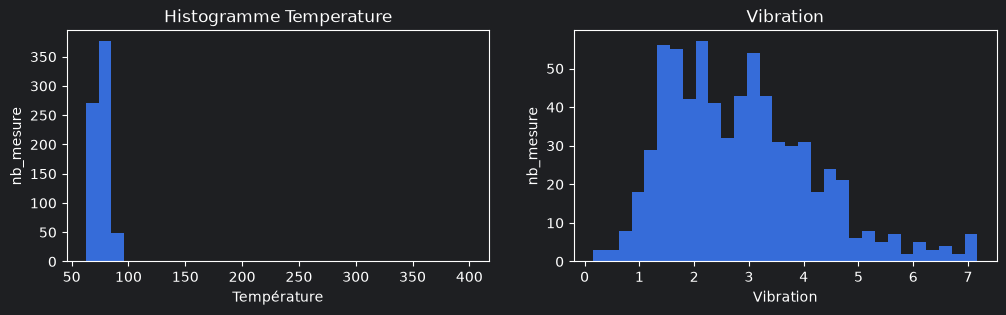

In [6]:
fig, axes = plt.subplots(1,2, figsize=(12,3))
axes[0].hist(df["temperature"].dropna(), bins=30)
axes[1].hist(df["vibration"].dropna(), bins=30)
axes[0].set_title("Histogramme Temperature")
axes[1].set_title("Vibration")
axes[0].set_xlabel("Température")
axes[1].set_xlabel("Vibration")
axes[0].set_ylabel("nb_mesure")
axes[1].set_ylabel("nb_mesure")

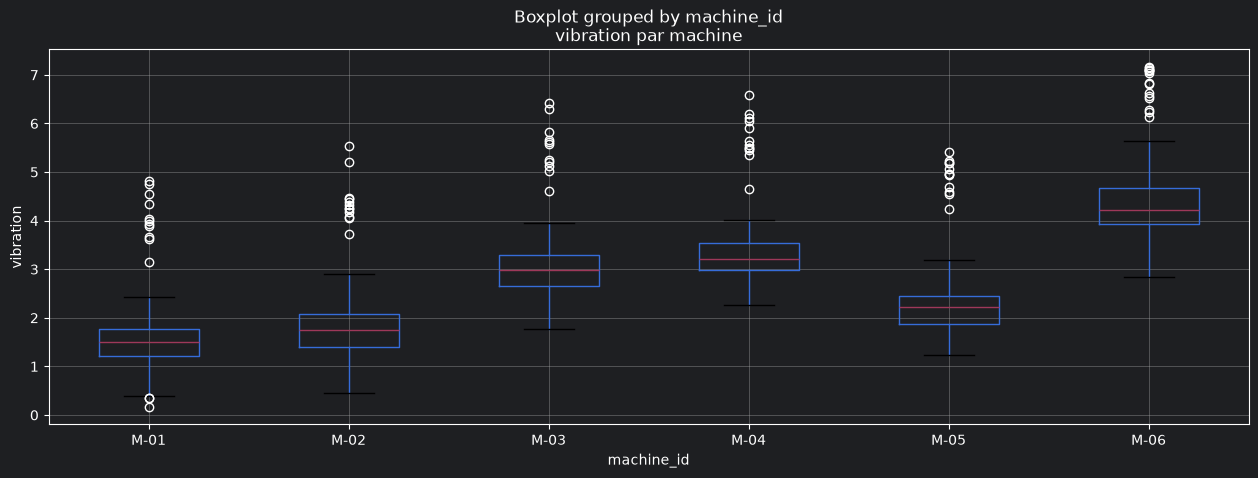

In [7]:
df.boxplot(column="vibration", by="machine_id", figsize=(15,5))
plt.title("vibration par machine")
plt.xlabel("machine_id")
plt.ylabel("vibration")
plt.show()

## 4. Découpage chronologique.

In [13]:
df["horodatage"] = pd.to_datetime(df["horodatage"])

coupure = df["horodatage"].quantile(0.6)
train = df[df["horodatage"] <= coupure]
test = df[df["horodatage"] > coupure]

## 5. Imputations

In [9]:
imputer_med = SimpleImputer(strategy="median").fit(train[col])
X_train_med = imputer_med.transform(train[col])
X_test_med = imputer_med.transform(test[col])

imputer_mean = SimpleImputer(strategy="mean").fit(train[col])
X_train_mean = imputer_mean.transform(train[col])
X_test_mean = imputer_mean.transform(test[col])

print(f"Imputations par la médiane : {X_train_med[0][0]}, {X_train_med[5][0]}, {X_train_med[15][0]} \nImputations par la moyenne : {X_test_mean[0][0]}, {X_test_mean[5][0]}, {X_train_med[15][0]}"  )

print("\n\n\nLa médiane est préférable à la moyenne car l'influence que les pics parasites ont sur celle-ci \nest moins importante que pour la moyenne")

Imputations par la médiane : 400.6703775754598, 65.68446873386465, 65.28356020820854 
Imputations par la moyenne : 84.22804316002417, 79.41220423574698, 65.28356020820854



La médiane est préférable à la moyenne car l'influence que les pics parasites ont sur celle-ci 
est moins importante que pour la moyenne


## 6. Encodage.

In [12]:
rng = np.random.default_rng(seed=42)
df["niveau charge"] = rng.choice(["faible", "moyen", "fort"], size=len(df))
df["equipe"] = rng.choice(["matin", "soir"], size=len(df))
#Création de la colonne niveau de charge qui n'est pas présente dans le csv


In [14]:
onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ordinal = OrdinalEncoder(categories=[["faible", "moyen", "fort"]])
categorie_train = onehot.fit_transform(train[["machine_id", "equipe"]])
categorie_test = onehot.transform(test[["machine_id", "equipe"]])
charge_train = ordinal.fit_transform(train[["niveau charge"]])
charge_test = ordinal.transform(test[["niveau charge"]])
charge_train

print("Il y a 6 colonnes pour le categorie_train pour toutes les valeurs encodées M_01,2,3 / Matin, soir. et le numéro de la colonne. \n Le charge_train prends 1 seule colonne car l'ordinal encoder standardise directement la valeur ")

Il y a 6 colonnes pour le categorie_train pour toutes les valeurs encodées M_01,2,3 / Matin, soir. et le numéro de la colonne. 
 Le charge_train prends 1 seule colonne car l'ordinal encoder standardise directement la valeur 


## 7. Standardisation

In [15]:
std = StandardScaler().fit(X_train_med)
X_train_std, X_test_std = std.transform(X_train_med), std.transform(X_test_med)

In [22]:
std = StandardScaler().fit(X_train_med)
X_train_std, X_test_std = std.transform(X_train_med), std.transform(X_test_med)
print("Moyennes après standardisation (train / test) :", X_train_std.mean(axis=0).round(2), X_test_std.mean(axis=0).round(2))
print("Écart-types après standardisation (train / test :", X_train_std.std(axis=0).round(2), X_test_std.std(axis=0).round(2))

Moyennes après standardisation (train / test) : [ 0. -0. -0.  0.] [ 0.26  0.85  0.83 -0.93]
Écart-types après standardisation (train / test : [1. 1. 1. 1.] [0.34 1.19 1.1  1.09]


La moyenne du test n'est pas égale à zéro, les valeurs dans le dataset de test ne sont ainsi pas égales à celles du train

## 8. Distance

In [20]:
A = df.loc[df["machine_id"] == "M-01", col].dropna().iloc[0].to_numpy()
B = df.loc[df["machine_id"] == "M-06", col].dropna().iloc[0].to_numpy()

print("Euclidienne :", euclidean(A, B))   # racine de la somme des carrés des écarts
print("Manhattan   :", cityblock(A, B))   # somme des écarts absolus
print("Cosinus     :", cosine(A, B))      # 1 - cos(angle) : compare les proportions



Euclidienne : 315.65888043586824
Manhattan   : 348.9134782496125
Cosinus     : 0.03416348438047645


### Distance standardisee

La standardisation est réalisée avec les paramètres appris sur les données d'entraînement (`train`) : chaque variable est soustraite de sa moyenne puis divisée par son écart-type. Les distances sont ensuite calculées sur les vecteurs `A_std` et `B_std`. Ainsi, les variables ayant des unités ou des variances différentes contribuent de façon comparable au résultat.

Cette distance standardisee est plus pertinente que la distance brute, car elle evite qu'une variable exprimee avec une grande echelle numerique domine les trois autres.